In [37]:
# Cell 1: Imports and project paths

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# Get current working directory
CURRENT_DIR = Path.cwd()

# Detect project root
if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
elif (CURRENT_DIR / "datasets").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "datasets").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Define project directories
DATA_PATH = PROJECT_ROOT / "datasets"
RAW_DATA_PATH = DATA_PATH / "raw"
PROCESSED_DATA_PATH = DATA_PATH / "processed"
REPORTS_PATH = PROJECT_ROOT / "reports"

# Reproducibility
RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)
print("Processed data path:", PROCESSED_DATA_PATH)
print("Reports path:", REPORTS_PATH)

Project root: /Users/adityachaubey/Desktop/RetailAI
Processed data path: /Users/adityachaubey/Desktop/RetailAI/datasets/processed
Reports path: /Users/adityachaubey/Desktop/RetailAI/reports


In [40]:
# Cell 2: Load processed datasets

# Load customer data
customers = pd.read_parquet(
    PROCESSED_DATA_PATH / "customers.parquet"
)

# Load order data
orders = pd.read_parquet(
    PROCESSED_DATA_PATH / "orders.parquet"
)

# Load payment data
order_payments = pd.read_parquet(
    PROCESSED_DATA_PATH / "order_payments.parquet"
)

print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Payments:", order_payments.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Order Payments: (103886, 5)


In [41]:
# Load the customer dataset from the processed data layer.
customers = pd.read_parquet(
    PROCESSED_DATA_PATH / "customers.parquet"
)

# Load the orders dataset.
orders = pd.read_parquet(
    PROCESSED_DATA_PATH / "orders.parquet"
)

# Load the order payments dataset.
order_payments = pd.read_parquet(
    PROCESSED_DATA_PATH / "order_payments.parquet"
)

# Print the shapes of the loaded datasets.
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Payments:", order_payments.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Order Payments: (103886, 5)


In [42]:
# Count the number of customer records.
customer_records = customers["customer_id"].nunique()

# Count the number of actual unique customers.
unique_customers = customers["customer_unique_id"].nunique()

# Calculate how many customer records exist per unique customer on average.
customer_record_ratio = (
    customer_records / unique_customers
)

# Display the identity statistics.
customer_identity = pd.DataFrame({
    "metric": [
        "Customer records",
        "Unique customers",
        "Records per unique customer"
    ],
    "value": [
        customer_records,
        unique_customers,
        customer_record_ratio
    ]
})

customer_identity

,metric,value
0,Customer records,"99,441.00"
1,Unique customers,"96,096.00"
2,Records per unique customer,1.03


In [43]:
# Display the number of orders in each order status.
order_status_summary = (
    orders["order_status"]
    .value_counts()
    .rename_axis("order_status")
    .reset_index(name="order_count")
)

# Display the order status distribution.
order_status_summary

,order_status,order_count
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [44]:
# Keep only successfully delivered orders for customer purchase analysis.
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Print the number of delivered orders.
print(
    f"Delivered orders: {len(delivered_orders):,}"
)

Delivered orders: 96,478


In [45]:
# Aggregate all payment records belonging to the same order.
order_revenue = (
    order_payments
    .groupby("order_id", as_index=False)
    ["payment_value"]
    .sum()
)

# Rename payment_value to order_revenue for clarity.
order_revenue = order_revenue.rename(
    columns={
        "payment_value": "order_revenue"
    }
)

# Display the first few order-level revenue records.
order_revenue.head()

,order_id,order_revenue
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [47]:
# Cell 8: Build customer transaction table

# Select required order-level information
customer_orders = delivered_orders[
    [
        "order_id",
        "customer_id",
        "order_purchase_timestamp"
    ]
].copy()

# Convert purchase timestamp to datetime
customer_orders["order_purchase_timestamp"] = pd.to_datetime(
    customer_orders["order_purchase_timestamp"],
    errors="coerce"
)

# Add the actual unique customer identifier
customer_orders = customer_orders.merge(
    customers[
        [
            "customer_id",
            "customer_unique_id"
        ]
    ],
    on="customer_id",
    how="left"
)

# Calculate total payment value for each order
order_revenue = (
    order_payments
    .groupby("order_id")["payment_value"]
    .sum()
    .reset_index()
)

# Rename the revenue column clearly
order_revenue = order_revenue.rename(
    columns={
        "payment_value": "order_revenue"
    }
)

# Merge order-level revenue
customer_orders = customer_orders.merge(
    order_revenue,
    on="order_id",
    how="left"
)

# Remove customers without a valid unique ID
customer_orders = customer_orders.dropna(
    subset=["customer_unique_id"]
)

# Fill missing revenue with zero
customer_orders["order_revenue"] = (
    customer_orders["order_revenue"]
    .fillna(0)
)

print("Customer transaction table shape:")
print(customer_orders.shape)

display(customer_orders.head())

Customer transaction table shape:
(96478, 5)


,order_id,customer_id,order_purchase_timestamp,customer_unique_id,order_revenue
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,72632f0f9dd73dfee390c9b22eb56dd6,28.62


In [48]:
# Cell 9: Create customer-level RFM and behavioral features

# Define the analysis snapshot date
snapshot_date = customer_orders[
    "order_purchase_timestamp"
].max()

print("Snapshot date:", snapshot_date)

# Create customer-level features
rfm = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        # Days since the customer's last purchase
        recency=(
            "order_purchase_timestamp",
            lambda x: (snapshot_date - x.max()).days
        ),

        # Number of unique orders
        frequency=(
            "order_id",
            "nunique"
        ),

        # Total amount spent by the customer
        monetary=(
            "order_revenue",
            "sum"
        ),

        # First purchase date
        first_purchase=(
            "order_purchase_timestamp",
            "min"
        ),

        # Last purchase date
        last_purchase=(
            "order_purchase_timestamp",
            "max"
        )
    )
    .reset_index()
)

# Calculate customer lifetime
rfm["customer_lifetime_days"] = (
    rfm["last_purchase"]
    - rfm["first_purchase"]
).dt.days

# Avoid zero lifetime for one-time customers
rfm["customer_lifetime_days"] = (
    rfm["customer_lifetime_days"]
    .clip(lower=1)
)

# Calculate Average Order Value
rfm["aov"] = (
    rfm["monetary"]
    / rfm["frequency"]
)

# Calculate active months
# Minimum one month prevents artificial high purchase rates
active_months = np.maximum(
    rfm["customer_lifetime_days"] / 30,
    1
)

# Calculate orders per 30 days
rfm["orders_per_30_days"] = (
    rfm["frequency"]
    / active_months
)

# Handle invalid values
rfm["orders_per_30_days"] = (
    rfm["orders_per_30_days"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

print("RFM table shape:", rfm.shape)

display(rfm.head())

Snapshot date: 2018-08-29 15:00:37
RFM table shape: (93358, 9)


,customer_unique_id,recency,frequency,monetary,first_purchase,last_purchase,customer_lifetime_days,aov,orders_per_30_days
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,2018-05-10 10:56:27,2018-05-10 10:56:27,1,141.90,1.00
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,2018-05-07 11:11:27,2018-05-07 11:11:27,1,27.19,1.00
2,0000f46a3911fa3c0805444483337064,536,1,86.22,2017-03-10 21:05:03,2017-03-10 21:05:03,1,86.22,1.00
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2017-10-12 20:29:41,2017-10-12 20:29:41,1,43.62,1.00
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2017-11-14 19:45:42,2017-11-14 19:45:42,1,196.89,1.00


In [25]:
# Calculate purchase intensity more realistically
# A one-time customer should not appear to have an extremely high
# monthly purchase rate simply because their lifetime is one day.

active_months = np.maximum(
    rfm["customer_lifetime_days"] / 30,
    1
)

rfm["orders_per_30_days"] = (
    rfm["frequency"] / active_months
)

# Replace infinite values
rfm["orders_per_30_days"] = (
    rfm["orders_per_30_days"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

In [49]:
# Cell 11: Validate customer-level features

feature_columns = [
    "recency",
    "frequency",
    "monetary",
    "aov",
    "customer_lifetime_days",
    "orders_per_30_days"
]

# Check missing values
print("Missing values:")
display(
    rfm[feature_columns].isna().sum()
)

# Check infinite values
print("\nInfinite values:")

numeric_data = rfm[feature_columns].select_dtypes(
    include=np.number
)

print(
    np.isinf(numeric_data).sum()
)

# Check invalid values
print(
    "\nCustomers with invalid frequency:",
    (rfm["frequency"] <= 0).sum()
)

print(
    "Customers with invalid monetary:",
    (rfm["monetary"] <= 0).sum()
)

# Display descriptive statistics
print("\nFeature statistics:")

display(
    rfm[feature_columns].describe().T
)

Missing values:


recency                   0
frequency                 0
monetary                  0
aov                       0
customer_lifetime_days    0
orders_per_30_days        0
dtype: int64


Infinite values:
recency                   0
frequency                 0
monetary                  0
aov                       0
customer_lifetime_days    0
orders_per_30_days        0
dtype: int64

Customers with invalid frequency: 0
Customers with invalid monetary: 1

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
recency,"93,358.00",236.94,152.59,0.00,113.00,218.00,345.00,713.00
frequency,"93,358.00",1.03,0.21,1.00,1.00,1.00,1.00,15.00
monetary,"93,358.00",165.20,226.31,0.00,63.05,107.78,182.56,"13,664.08"
aov,"93,358.00",160.31,219.57,0.00,62.37,105.63,176.65,"13,664.08"
customer_lifetime_days,"93,358.00",3.61,24.85,1.00,1.00,1.00,1.00,633.00
orders_per_30_days,"93,358.00",1.01,0.15,0.10,1.00,1.00,1.00,6.00


In [50]:
# Cell 12: Create improved RFM scores

rfm_scored = rfm.copy()

# -----------------------------
# Recency Score
# -----------------------------
# More recent customers receive higher scores.

recency_rank = rfm_scored["recency"].rank(
    method="first"
)

rfm_scored["R_score"] = pd.qcut(
    recency_rank,
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)


# -----------------------------
# Frequency Score
# -----------------------------
# Business-oriented frequency scoring.
# One-time customers are not treated as highly frequent.

def frequency_score(value):

    if value == 1:
        return 1
    elif value == 2:
        return 2
    elif value == 3:
        return 3
    elif value <= 5:
        return 4
    else:
        return 5


rfm_scored["F_score"] = (
    rfm_scored["frequency"]
    .apply(frequency_score)
)


# -----------------------------
# Monetary Score
# -----------------------------
# Higher spending receives higher scores.

monetary_rank = rfm_scored["monetary"].rank(
    method="first"
)

rfm_scored["M_score"] = pd.qcut(
    monetary_rank,
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)


# Combined RFM score
rfm_scored["RFM_score"] = (
    rfm_scored["R_score"]
    + rfm_scored["F_score"]
    + rfm_scored["M_score"]
)

display(
    rfm_scored[
        [
            "customer_unique_id",
            "recency",
            "frequency",
            "monetary",
            "R_score",
            "F_score",
            "M_score",
            "RFM_score"
        ]
    ].head(10)
)

,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,141.90,4,1,4,9
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,27.19,4,1,1,6
2,0000f46a3911fa3c0805444483337064,536,1,86.22,1,1,2,4
3,0000f6ccb0745a6a4b88665a16c9f078,320,1,43.62,2,1,1,4
4,0004aac84e0df4da2b147fca70cf8255,287,1,196.89,2,1,4,7
5,0004bd2a26a76fe21f786e4fbd80607f,145,1,166.98,4,1,4,9
6,00050ab1314c0e55a6ca13cf7181fecf,131,1,35.38,4,1,1,6
7,00053a61a98854899e70ed204dd4bafe,182,1,419.18,3,1,5,9
8,0005e1862207bf6ccc02e4228effd9a0,542,1,150.12,1,1,4,6
9,0005ef4cd20d2893f0d9fbd94d3c0d97,169,1,129.76,4,1,3,8


In [51]:
# Cell 13: Prepare behavioral features for clustering

rfm_ml = rfm_scored.copy()

# Log transformation reduces the effect of extreme values

rfm_ml["log_frequency"] = np.log1p(
    rfm_ml["frequency"]
)

rfm_ml["log_monetary"] = np.log1p(
    rfm_ml["monetary"]
)

rfm_ml["log_aov"] = np.log1p(
    rfm_ml["aov"]
)

rfm_ml["log_customer_lifetime"] = np.log1p(
    rfm_ml["customer_lifetime_days"]
)

rfm_ml["log_purchase_rate"] = np.log1p(
    rfm_ml["orders_per_30_days"]
)

# Features used for K-Means
clustering_features = [
    "recency",
    "log_frequency",
    "log_monetary",
    "log_aov",
    "log_customer_lifetime",
    "log_purchase_rate"
]

print("Clustering features:")
print(clustering_features)

display(
    rfm_ml[clustering_features].describe().T
)

Clustering features:
['recency', 'log_frequency', 'log_monetary', 'log_aov', 'log_customer_lifetime', 'log_purchase_rate']


,count,mean,std,min,25%,50%,75%,max
recency,"93,358.00",236.94,152.59,0.00,113.00,218.00,345.00,713.00
log_frequency,"93,358.00",0.71,0.08,0.69,0.69,0.69,0.69,2.77
log_monetary,"93,358.00",4.73,0.81,0.00,4.16,4.69,5.21,9.52
log_aov,"93,358.00",4.71,0.80,0.00,4.15,4.67,5.18,9.52
log_customer_lifetime,"93,358.00",0.77,0.54,0.69,0.69,0.69,0.69,6.45
log_purchase_rate,"93,358.00",0.70,0.07,0.09,0.69,0.69,0.69,1.95


In [52]:
# Cell 14: Standardize clustering features

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    rfm_ml[clustering_features]
)

print(
    "Scaled feature matrix shape:",
    X_scaled.shape
)

Scaled feature matrix shape: (93358, 6)


In [53]:
# Cell 15: Evaluate different K values

cluster_results = []

# Test K values from 2 to 8
for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )

    labels = kmeans.fit_predict(X_scaled)

    # Calculate silhouette score
    silhouette = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(20000, len(X_scaled)),
        random_state=RANDOM_STATE
    )

    # Calculate cluster sizes
    cluster_sizes = pd.Series(
        labels
    ).value_counts()

    # Smallest cluster percentage
    smallest_cluster_percentage = (
        cluster_sizes.min()
        / len(labels)
        * 100
    )

    # Largest cluster percentage
    largest_cluster_percentage = (
        cluster_sizes.max()
        / len(labels)
        * 100
    )

    cluster_results.append({
        "k": k,
        "silhouette_score": silhouette,
        "smallest_cluster_percentage":
            smallest_cluster_percentage,
        "largest_cluster_percentage":
            largest_cluster_percentage
    })

cluster_results = pd.DataFrame(
    cluster_results
)

display(cluster_results)

,k,silhouette_score,smallest_cluster_percentage,largest_cluster_percentage
0,2,0.77,3.00,97.00
1,3,0.35,1.49,54.92
2,4,0.37,1.29,54.30
3,5,0.36,1.29,37.65
4,6,0.37,1.29,32.86
5,7,0.36,1.29,30.43
6,8,0.34,1.29,23.81


In [54]:
# Cell 16: Train the candidate final K-Means model

# Select K with the highest silhouette score
best_k = int(
    cluster_results.loc[
        cluster_results["silhouette_score"].idxmax(),
        "k"
    ]
)

print(
    "Best K based on silhouette score:",
    best_k
)

# Train final candidate K-Means model
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=20
)

# Assign clusters
rfm_ml["cluster"] = (
    final_kmeans.fit_predict(X_scaled)
)

print("\nCluster sizes:")

display(
    rfm_ml["cluster"]
    .value_counts()
    .sort_index()
)

Best K based on silhouette score: 2

Cluster sizes:


cluster
0     2801
1    90557
Name: count, dtype: int64

In [55]:
# Cell 17: Build detailed cluster profiles

cluster_profile = (
    rfm_ml
    .groupby("cluster")
    .agg(
        customers=("customer_unique_id", "count"),

        avg_recency=("recency", "mean"),
        median_recency=("recency", "median"),

        avg_frequency=("frequency", "mean"),
        median_frequency=("frequency", "median"),

        avg_monetary=("monetary", "mean"),
        median_monetary=("monetary", "median"),

        avg_aov=("aov", "mean"),

        avg_lifetime=(
            "customer_lifetime_days",
            "mean"
        ),

        avg_purchase_rate=(
            "orders_per_30_days",
            "mean"
        ),

        avg_rfm_score=(
            "RFM_score",
            "mean"
        ),

        avg_r_score=("R_score", "mean"),
        avg_f_score=("F_score", "mean"),
        avg_m_score=("M_score", "mean")
    )
    .reset_index()
)

# Calculate customer percentage
cluster_profile["customer_percentage"] = (
    cluster_profile["customers"]
    / len(rfm_ml)
    * 100
).round(2)

display(cluster_profile)

,cluster,customers,avg_recency,median_recency,avg_frequency,median_frequency,avg_monetary,median_monetary,avg_aov,avg_lifetime,avg_purchase_rate,avg_rfm_score,avg_r_score,avg_f_score,avg_m_score,customer_percentage
0,0,2801,219.29,198.00,2.11,2.00,308.59,225.55,145.87,88.08,1.33,9.52,3.14,2.10,4.27,3.00
1,1,90557,237.49,218.00,1.00,1.00,160.76,105.39,160.76,1.00,1.00,6.96,3.00,1.00,2.96,97.00


In [56]:
# Cell 18: Map clusters to business segments

# Rank clusters by average RFM score
cluster_ranking = (
    cluster_profile
    .sort_values(
        "avg_rfm_score",
        ascending=False
    )
    .reset_index(drop=True)
)

# Create business-oriented labels
if len(cluster_ranking) == 2:

    segment_names = [
        "Repeat High-Value Customers",
        "One-Time / Low-Engagement Customers"
    ]

elif len(cluster_ranking) == 3:

    segment_names = [
        "High-Value Customers",
        "Potential Loyalists",
        "One-Time / Low-Engagement Customers"
    ]

elif len(cluster_ranking) == 4:

    segment_names = [
        "Champions",
        "Loyal Customers",
        "Potential Loyalists",
        "At-Risk Customers"
    ]

else:

    segment_names = [
        "Champions",
        "Loyal Customers",
        "Potential Loyalists",
        "High-Value At-Risk",
        "At-Risk Customers",
        "Occasional Customers",
        "Low-Value Customers",
        "Inactive Customers"
    ]

# Create cluster-to-segment mapping
cluster_to_segment = {}

for index, row in cluster_ranking.iterrows():

    cluster_id = row["cluster"]

    cluster_to_segment[cluster_id] = (
        segment_names[index]
    )

print("Cluster → Business Segment")

for cluster_id, segment in cluster_to_segment.items():
    print(
        f"Cluster {cluster_id} → {segment}"
    )

Cluster → Business Segment
Cluster 0.0 → Repeat High-Value Customers
Cluster 1.0 → One-Time / Low-Engagement Customers


In [57]:
# Cell 19: Create final customer segmentation dataset

# Apply business segment labels
rfm_ml["customer_segment"] = (
    rfm_ml["cluster"]
    .map(cluster_to_segment)
)

# Select final customer-level columns
customer_segments = rfm_ml[
    [
        "customer_unique_id",
        "recency",
        "frequency",
        "monetary",
        "aov",
        "customer_lifetime_days",
        "orders_per_30_days",
        "R_score",
        "F_score",
        "M_score",
        "RFM_score",
        "cluster",
        "customer_segment"
    ]
].copy()

# Sort by RFM score
customer_segments = (
    customer_segments
    .sort_values(
        "RFM_score",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    customer_segments.head(20)
)

,customer_unique_id,recency,frequency,monetary,aov,customer_lifetime_days,orders_per_30_days,R_score,F_score,M_score,RFM_score,cluster,customer_segment
0,6469f99c1f9dfae7733b25662e7f1782,62,7,758.83,108.40,281,0.75,5,5,5,15,0,Repeat High-Value Customers
1,8d50f5eadf50201ccdcedfb9e2ac8455,8,15,879.27,58.62,427,1.05,5,5,5,15,0,Repeat High-Value Customers
2,dc813062e0fc23409cd255f7f53c7074,6,6,"1,094.63",182.44,417,0.43,5,5,5,15,0,Repeat High-Value Customers
3,ca77025e7201e3b30c44b472ff346268,89,7,"1,122.72",160.39,234,0.90,5,5,5,15,0,Repeat High-Value Customers
4,b896655e2083a1d76b7b85df8fc86e40,54,4,507.06,126.77,283,0.42,5,4,5,14,0,Repeat High-Value Customers
5,4facc2e6fbc2bffab2fea92d2b4aa7e4,15,4,"1,760.75",440.19,420,0.29,5,4,5,14,0,Repeat High-Value Customers
6,795c1622cf7a53d63d324e862349d01c,11,4,354.23,88.56,213,0.56,5,4,5,14,0,Repeat High-Value Customers
7,394ac4de8f3acb14253c177f0e15bc58,13,5,745.41,149.08,235,0.64,5,4,5,14,0,Repeat High-Value Customers
8,fe81bb32c243a86b2f86fbf053fe6140,69,5,"1,590.76",318.15,242,0.62,5,4,5,14,0,Repeat High-Value Customers
9,397b44d5bb99eabf54ea9c2b41ebb905,72,4,"1,756.53",439.13,157,0.76,5,4,5,14,0,Repeat High-Value Customers


In [58]:
# Cell 20: Create segment-level business summary

segment_summary = (
    customer_segments
    .groupby("customer_segment")
    .agg(
        customers=("customer_unique_id", "count"),

        avg_recency=("recency", "mean"),

        avg_frequency=("frequency", "mean"),

        avg_monetary=("monetary", "mean"),

        avg_aov=("aov", "mean"),

        avg_lifetime=(
            "customer_lifetime_days",
            "mean"
        ),

        avg_purchase_rate=(
            "orders_per_30_days",
            "mean"
        ),

        total_revenue=("monetary", "sum"),

        avg_rfm_score=("RFM_score", "mean")
    )
    .reset_index()
)

# Customer percentage
segment_summary["customer_percentage"] = (
    segment_summary["customers"]
    / segment_summary["customers"].sum()
    * 100
).round(2)

# Revenue percentage
segment_summary["revenue_percentage"] = (
    segment_summary["total_revenue"]
    / segment_summary["total_revenue"].sum()
    * 100
).round(2)

# Sort by revenue
segment_summary = (
    segment_summary
    .sort_values(
        "total_revenue",
        ascending=False
    )
    .reset_index(drop=True)
)

display(segment_summary)

,customer_segment,customers,avg_recency,avg_frequency,avg_monetary,avg_aov,avg_lifetime,avg_purchase_rate,total_revenue,avg_rfm_score,customer_percentage,revenue_percentage
0,One-Time / Low-Engagement Customers,90557,237.49,1.00,160.76,160.76,1.00,1.00,"14,558,104.56",6.96,97.00,94.40
1,Repeat High-Value Customers,2801,219.29,2.11,308.59,145.87,88.08,1.33,"864,357.21",9.52,3.00,5.60


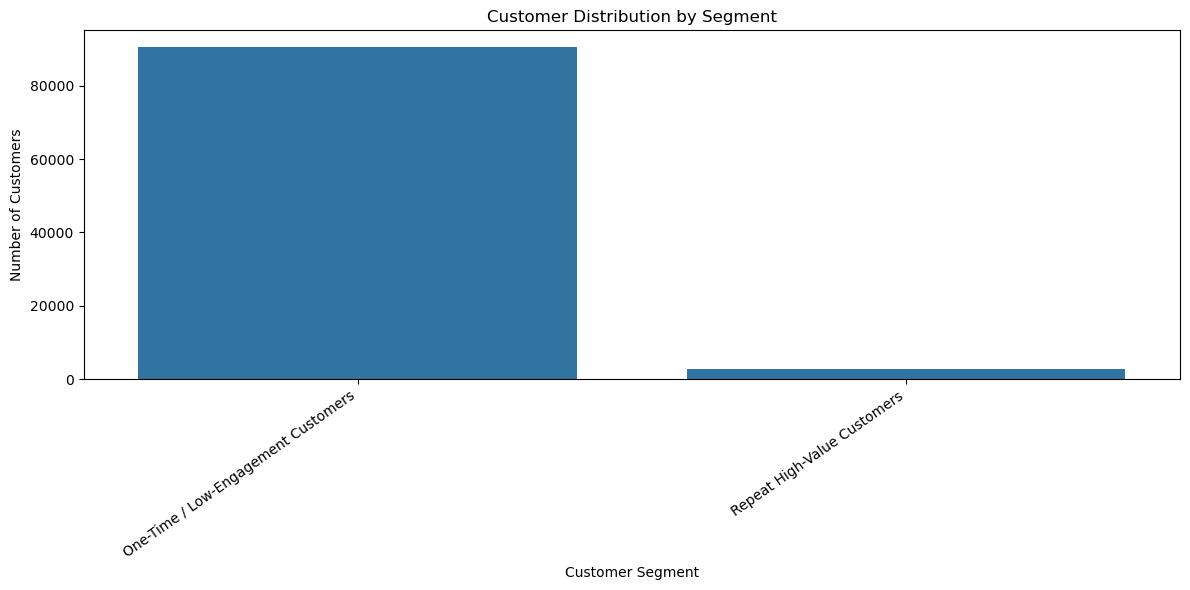

In [59]:
# Cell 21: Visualize customer distribution by segment

plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_summary,
    x="customer_segment",
    y="customers"
)

plt.title(
    "Customer Distribution by Segment"
)

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

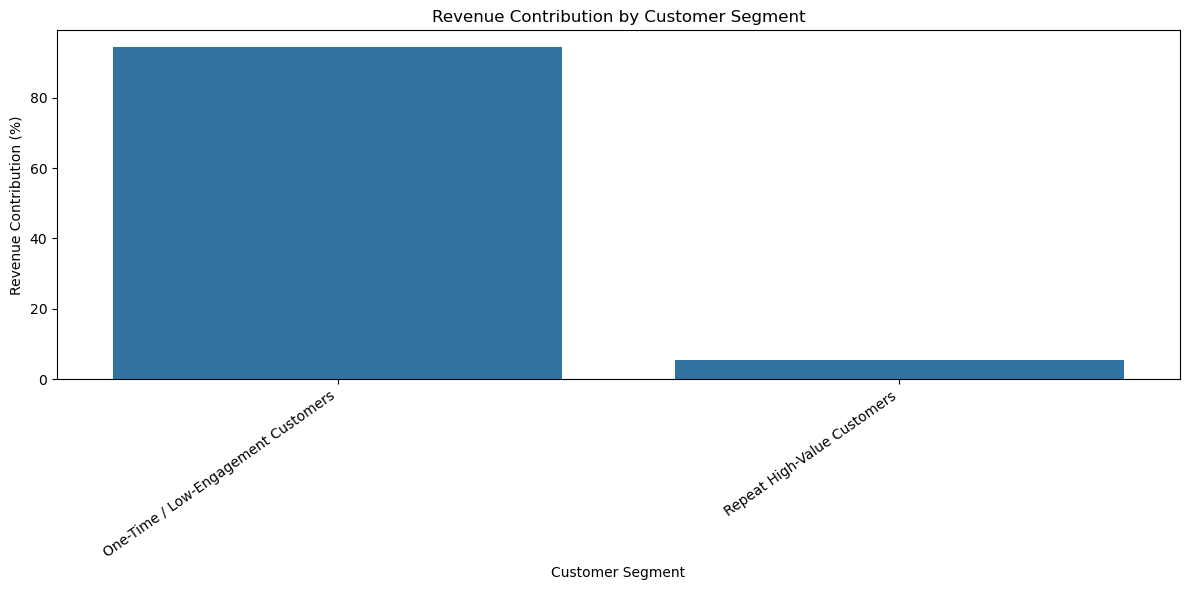

In [60]:
# Cell 22: Visualize revenue contribution by segment

plt.figure(figsize=(12, 6))

sns.barplot(
    data=segment_summary,
    x="customer_segment",
    y="revenue_percentage"
)

plt.title(
    "Revenue Contribution by Customer Segment"
)

plt.xlabel("Customer Segment")
plt.ylabel("Revenue Contribution (%)")

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

In [61]:
# Cell 23: Save final segmentation results

# Define output paths
segmentation_output = (
    PROCESSED_DATA_PATH
    / "customer_segments.csv"
)

segment_summary_output = (
    REPORTS_PATH
    / "customer_segment_summary.csv"
)

# Save customer-level segmentation
customer_segments.to_csv(
    segmentation_output,
    index=False
)

# Save segment-level summary
segment_summary.to_csv(
    segment_summary_output,
    index=False
)

print("✓ Customer segments saved to:")
print(segmentation_output)

print("\n✓ Segment summary saved to:")
print(segment_summary_output)

✓ Customer segments saved to:
/Users/adityachaubey/Desktop/RetailAI/datasets/processed/customer_segments.csv

✓ Segment summary saved to:
/Users/adityachaubey/Desktop/RetailAI/reports/customer_segment_summary.csv
